# Adding Source to the Numerical 1D-Diffusion

This notebook models the spread of a pollutant released at $x = 0$ using the one-dimensional advection and diffusion equation by adding the source term representing the pollutant:

$$
\partial_{t}C(x,t)+u\partial_{x}C(x,t) = D \partial_{xx}C(x,t)+S(x,t)
$$

where:

C(x,t) is the pollutant concentration.

u is the wind velocity.

D is the diffusion coefficient.

S(x,t) is the source term, describing the rate of pollutant introduction at a given position and time

With the following boundary conditions

\begin{align}
    C(x,0) &= \delta(x) && \text{on },\\
    C(\pm L, t) &= 0 && \text{on },\\
    C_x(x,0) &= && \text{in }.
\end{align}

If we are considering the continuous point source of the pollutant:

$S(x,t)=q(t)\delta(x)$ where $q(t)$ is the pollutant emission rate, the source can be constant or vary with time.


In [1]:
# Window resizing
from IPython.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))
display(HTML("<style>.output_resu1lt { width:90% !important; }</style>"))
display(HTML(""" <style>.output_png { display: table-cell; text-align: center; vertical-align: middle; }</style> """))
display(HTML("<style> div.text_cell_render { line-height: 2.0; } </style>"))    # Adjust linespread

In [2]:
# Baseline packages
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation
from scipy.sparse        import diags_array
from scipy.sparse.linalg import spsolve
%matplotlib inline

In [3]:
def I_1(x, M, delta_x):
    C0 = np.zeros_like(x, dtype=float)
    C0[len(x) // 2] = M / delta_x      # at x==0 C0[]
    return C0


b_1 = [0.0, 0.0]    # u(0,t) = b_0, u(1,t) = b_L

def exact_solution(x, t, k=1.0, mass=1.0):
    if t == 0:
        return np.zeros_like(x)  # delta initial condition is not finite at t=0 blows up

    return (
        mass / np.sqrt(4 * np.pi * k * t)
        * np.exp(-x**2 / (4 * k * t))
    )

### Solve difference equations:

In [4]:
# ** Set up a plotting function ** #

def plotting(U, x, t, max_y=None, exact_handle=exact_solution, x_range=None):
    markers = ['x','s','d','+','o','.']
    colours = ['xkcd:salmon','xkcd:golden rod','xkcd:teal','xkcd:purple','xkcd:slate','xkcd:silver']

    # choose some (almost arbitrary) display times
    N = len(t) - 1
    disp_times = [0, N//20, N//10, N//5, N//2, N]

    # Set up the figure
    fig, ax = plt.subplots(1, 1, figsize=(12, 5))

    # Dummy plot for legend titles
    ax.scatter([0], [0], color='white', label=r'Exact $u(x,t)$', lw=0)

    # Plot actual curves
    if exact_handle != None:
        for i, idx_t in enumerate(disp_times):
            label = 't = {0:.0e}'.format(t[idx_t]) if (0 < t[idx_t] < t[-1]) else 't = {0:.0f}'.format(t[idx_t])
            ax.plot(x, exact_handle(x,t[idx_t]),
        color="red",
        linestyle="--",
        label=label)

    ax.scatter([0], [0], color='white', label=r'Numerical $U(x,t)$', lw=0)
    for i, idx_t in enumerate(disp_times):
        label = 't = {0:.0e}'.format(t[idx_t]) if (0 < t[idx_t] < t[-1]) else 't = {0:.0f}'.format(t[idx_t])
        ax.plot(x, U[idx_t],
        linestyle='-',
        marker=markers[i],
        markevery=max(1, len(x)//40),
        color=colours[i],
        label=label)

    ax.legend(ncols = 2, loc = 'center',  bbox_to_anchor=(1.2, 0.5), title ='Comparison')
    if x_range:
        ax.set_xlim(x_range)
    else:
        ax.set_xlim(x[0], x[-1])

    ax.set_ylim(0,max_y)
    plt.xlabel("Space (x)")
    plt.ylabel("Solution")
    plt.grid()
    plt.show()

In [5]:
def solve_forward_source(D, q, L, T=200, N=1000, density=1, max_y=45, x_range=None, exact_handle=None, plot=True):
    Nx = int(density*L)
    t = np.linspace(0.0, T, N + 1)      # Time grid
    x = np.linspace(-L, L, Nx + 1)     # Space grid

    dx = x[1] - x[0]
    dt = t[1] - t[0]
    r = D*dt/(dx**2) # stability condition for diffusion

    print("r =", r)
    if r >= 0.5:
        print("Not stable")
        return

    U = np.zeros((N+1, Nx+1))
    U[:, 0] = 0
    U[:, -1] = 0
    U[0] = 0  # Initially clean air instead of I_1(x, mass, dx)

    source_index = np.argmin(np.abs(x))  # Point source at x = 0

    for n in range(0, N):
        S = np.zeros(Nx+1)
        S[source_index] = q(t[n]) / dx
        U[n+1, 1:-1] = (U[n, 1:-1]
                       + r*(U[n, :-2] - 2*U[n, 1:-1] + U[n, 2:])
                       + dt*S[1:-1])

    total_mass = U.sum(axis=1)*dx
    print("Final numerical mass:", total_mass[-1])
    if plot:
        plotting(U, x, t, max_y=max_y, x_range=x_range,
                 exact_handle=None)
    return U, x, t, total_mass

r = 0.1
Final numerical mass: 999.9999999998596


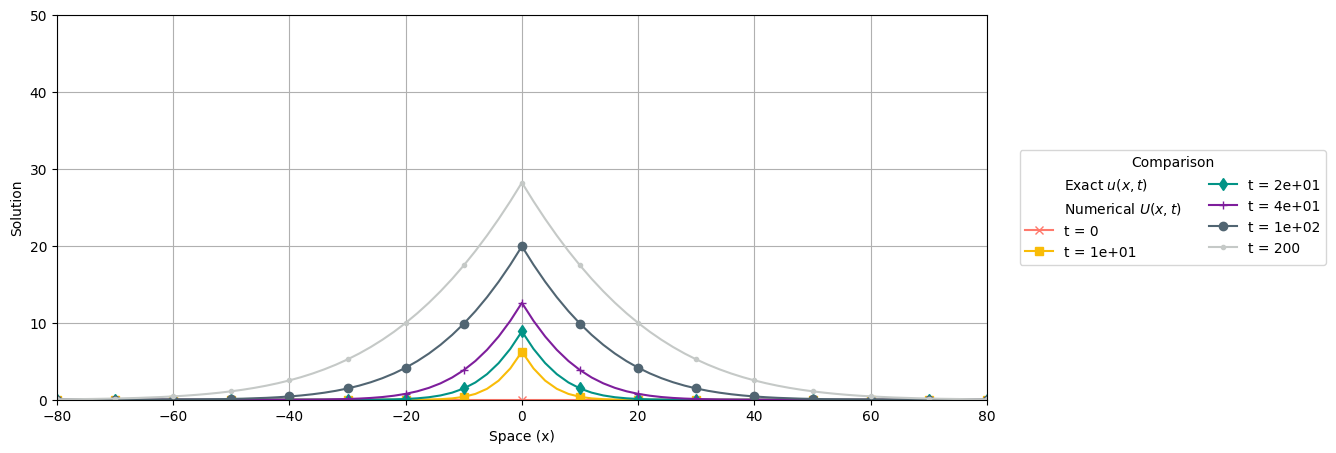

Expected injected amount: 1000.0


In [6]:
D, q0 = 2.0, 5.0

def q_constant(t):
    return q0

U, x, t, m = solve_forward_source(D, q_constant, L=200, N=1000,
                                  max_y=50, x_range=(-80, 80))
print("Expected injected amount:", q0*t[-1])

r = 0.1
Final numerical mass: 999.9999999998596


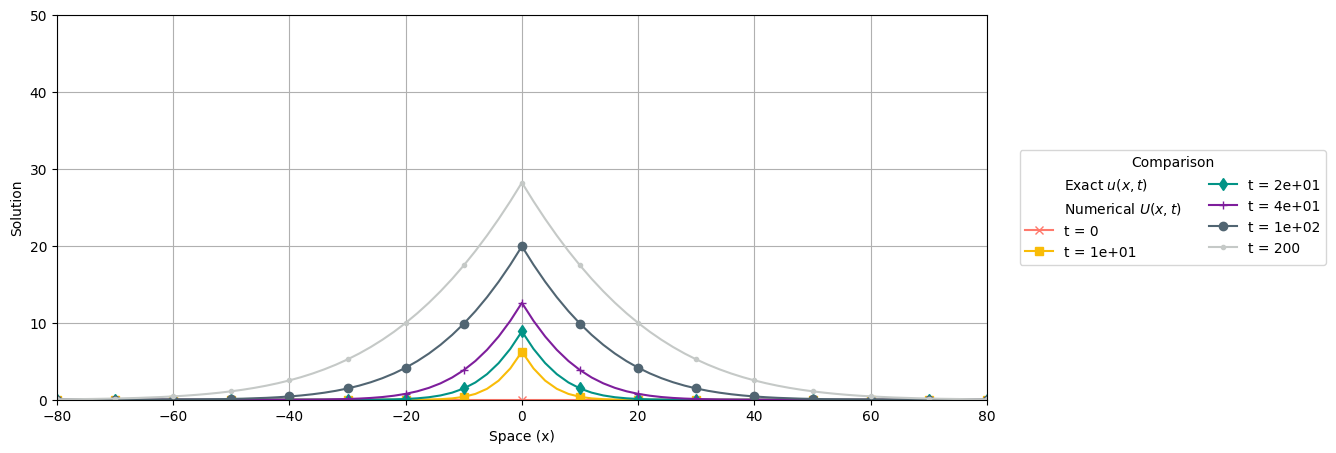

r = 0.1
Final numerical mass: 999.9999999999995


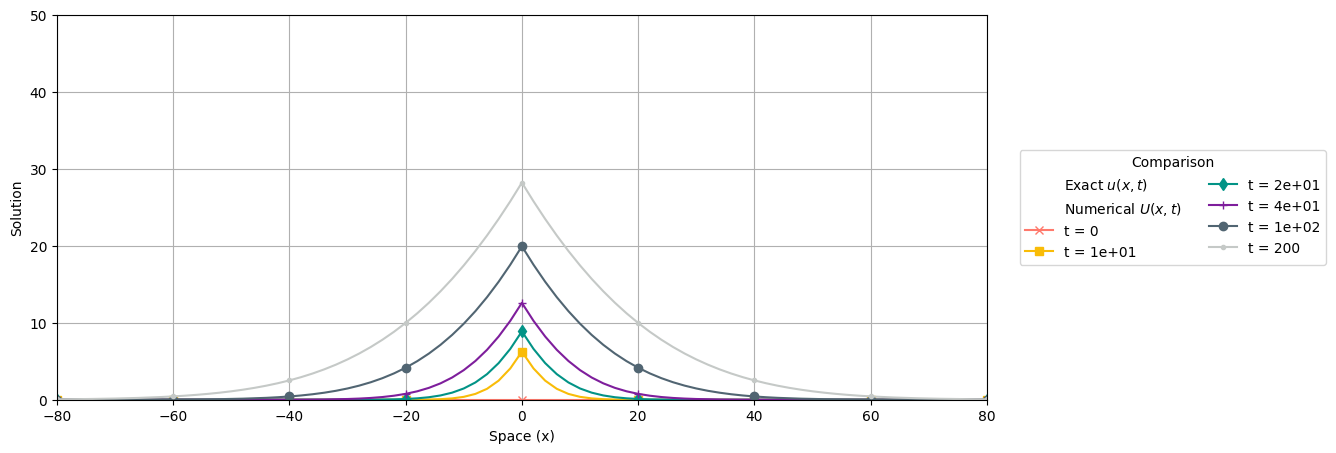

r = 0.1
Final numerical mass: 999.9999999999995


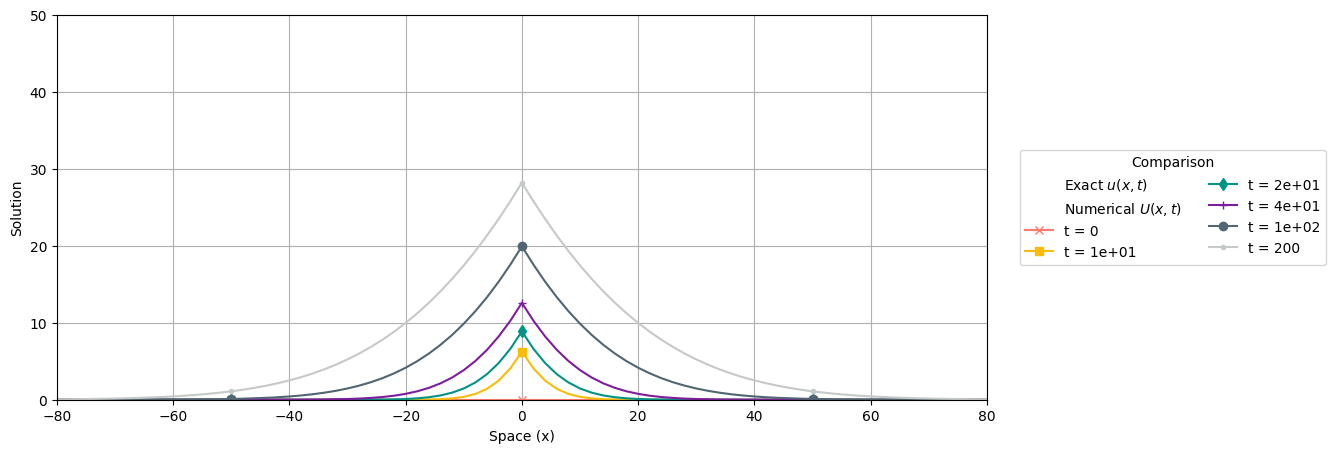

In [7]:
U1, x1, t1, m1 = solve_forward_source(D, q_constant, L=200, N=1000, max_y=50, x_range=(-80, 80))
U2, x2, t2, m2 = solve_forward_source(D, q_constant, L=400, N=1000, max_y=50, x_range=(-80, 80))
U3, x3, t3, m3 = solve_forward_source(D, q_constant, L=1000, N=1000, max_y=50, x_range=(-80, 80))

### backward euler

In [8]:
def solve_backward_source(D, q, L, T=200, N=1000, density=1, max_y=None, exact_handle=None, x_range=None, plot=True):
    t = np.linspace(0.0, T, N + 1)
    M = int(density*L)
    x = np.linspace(-L, L, M + 1)
    dx = x[1] - x[0]
    dt = t[1] - t[0]
    r = D*dt/(dx**2)

    # boundaries are fixed at zero
    A = diags_array(
        [(-r)*np.ones(M-2), (1+2*r)*np.ones(M-1),
         (-r)*np.ones(M-2)],
        offsets=(-1, 0, 1), shape=(M-1, M-1), format='csr'
    )

    U = np.zeros((N+1, M+1))
    source_index = np.argmin(np.abs(x))
    for n in range(N):
        S = np.zeros(M+1)
        S[source_index] = q(t[n+1]) / dx
        rhs = U[n, 1:-1] + dt*S[1:-1]
        U[n+1, 1:-1] = spsolve(A, rhs)

    total_mass = U.sum(axis=1)*dx
    print("Final numerical mass (Backward Euler):", total_mass[-1])
    if plot:
        plotting(U, x, t, max_y=max_y, exact_handle=None, x_range=x_range)
    return U, x, t, total_mass

r = 0.1
Final numerical mass: 499.9999999998596


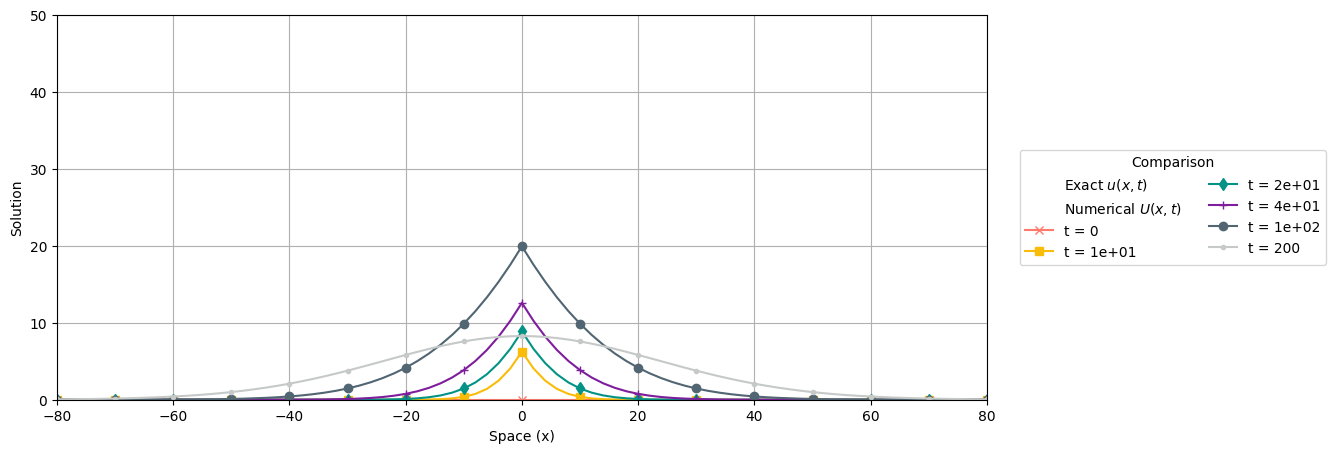

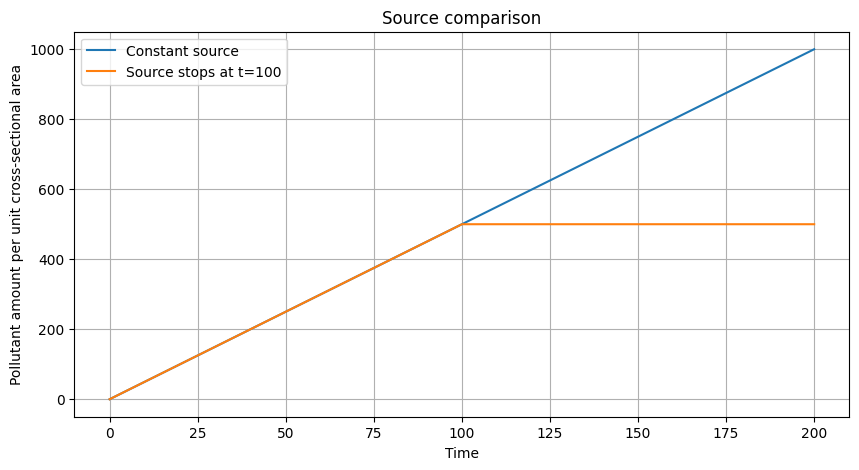

In [9]:
# Source testing: turn emissions off after t = 100

def q_variable(t):
    return q0 if t < 100 else 0.0

Uv, xv, tv, mv = solve_forward_source(D, q_variable, L=200, N=1000,
                                      max_y=50, x_range=(-80, 80))

plt.figure(figsize=(10, 5))
plt.plot(t, m, label="Constant source")
plt.plot(tv, mv, label="Source stops at t=100")
plt.xlabel("Time")
plt.ylabel("Pollutant amount per unit cross-sectional area")
plt.title("Source comparison")
plt.legend()
plt.grid()
plt.show()

In [10]:

for label, times, masses, rate in [
    ("Constant source", t, m, q_constant),
    ("Time-dependent source", tv, mv, q_variable),
]:
    dt = times[1] - times[0]
    injected = dt*sum(rate(time) for time in times[:-1])
    print(label)
    print("  Injected:", injected)
    print("  Numerical:", masses[-1])
    print("  Difference (includes boundary loss):", injected - masses[-1])

Constant source
  Injected: 1000.0
  Numerical: 999.9999999998596
  Difference (includes boundary loss): 1.404032445861958e-10
Time-dependent source
  Injected: 500.0
  Numerical: 499.9999999998596
  Difference (includes boundary loss): 1.404032445861958e-10


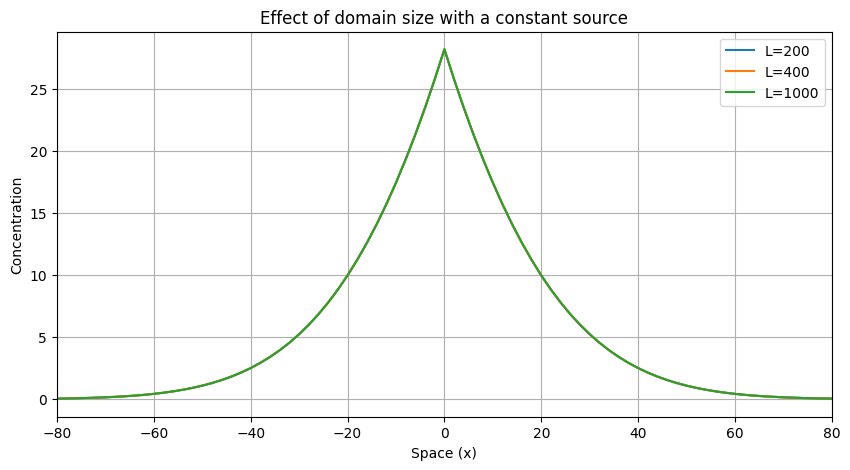

In [11]:

plt.figure(figsize=(10, 5))
for xx, UU, label in [(x1, U1, "L=200"),
                      (x2, U2, "L=400"),
                      (x3, U3, "L=1000")]:
    plt.plot(xx, UU[-1], label=label)
plt.xlim(-80, 80)
plt.xlabel("Space (x)")
plt.ylabel("Concentration")
plt.title("Effect of domain size with a constant source")
plt.legend()
plt.grid()
plt.show()

Final numerical mass (Backward Euler): 999.9999999997606


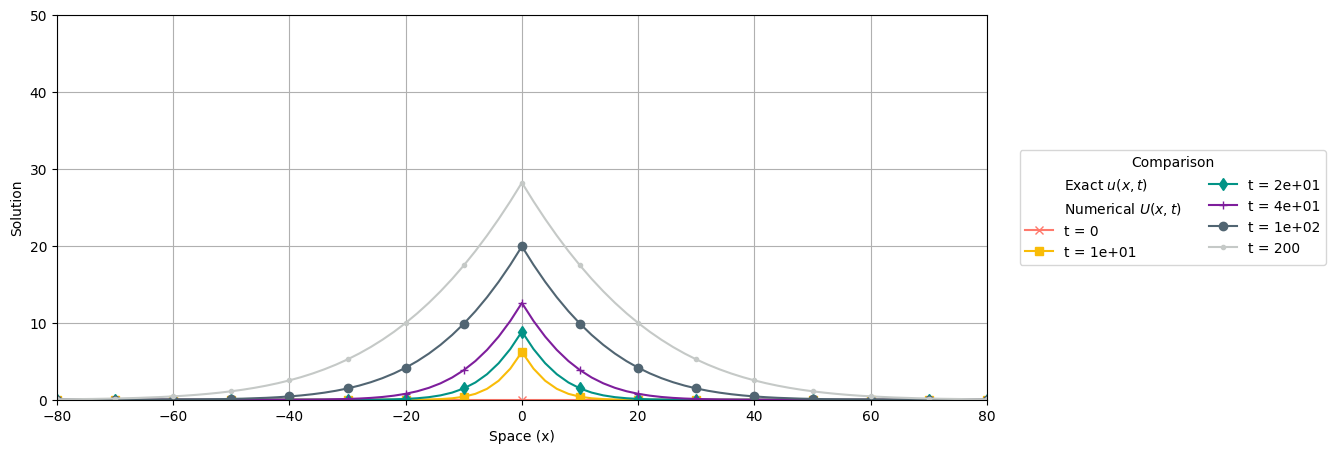

In [12]:

Ub, xb, tb, mb = solve_backward_source(
    D, q_constant, L=200, N=1000, max_y=50, x_range=(-80, 80)
)

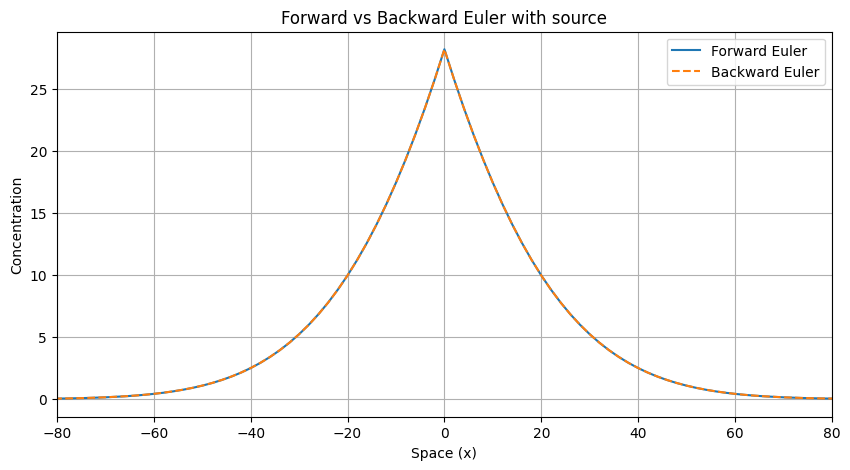

Maximum absolute difference: 0.007065655155773953


In [13]:

plt.figure(figsize=(10, 5))
plt.plot(x, U[-1], label="Forward Euler")
plt.plot(xb, Ub[-1], '--', label="Backward Euler")
plt.xlim(-80, 80)
plt.xlabel("Space (x)")
plt.ylabel("Concentration")
plt.title("Forward vs Backward Euler with source")
plt.legend()
plt.grid()
plt.show()
print("Maximum absolute difference:", np.max(np.abs(U[-1]-Ub[-1])))